# End-to-End PneumoniaMNIST ORD Pipeline: 4-Way ResNet-18 Comparison

This notebook adapts the original BreastMNIST experiments to **PneumoniaMNIST**, a binary classification dataset of 28 × 28 grayscale pediatric chest X-rays.

- Native labels: **0 = Normal (minority)**, **1 = Pneumonia (majority)**.
- Official MedMNIST splits: **4,708 training, 524 validation, 624 test**. The validation set is shared across all four classifiers and never used for ORD, DDPM, or augmentation. The original test set is used only for final evaluation of each model.
- Model 1: original imbalanced training data.
- Model 2: overlap-removed training data, using 5-fold out-of-fold majority confidence scoring with $\tau=0.3$ (remove if $P(y=1)\leq0.7$).
- Model 3: ORD + class-conditional DDPM synthesis of the smaller remaining class until counts match.
- Model 4: ORD + classical augmentation (rotation, scaling, Gaussian noise) of the smaller remaining class until counts match.
- Compare overall accuracy, balanced accuracy, per-class recall, macro F1, minority F1, ROC-AUC and confusion matrices. Per-class improvements are reported in percentage points relative to Model 1.

The architecture and training hyperparameters from the source notebook are retained. A single real validation set replaces the original per-model split of processed data so augmented or generated data cannot leak into validation. GPU recommended.

Dataset reference: [MedMNIST](https://medmnist.com/).

In [1]:
import copy
import math
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.models as models
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import KFold, train_test_split
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)
import medmnist
from medmnist import INFO

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

Using device: cuda


## Step 1: Load PneumoniaMNIST — Official Train, Validation and Test Splits

In [2]:
data_flag = 'pneumoniamnist'
info = INFO[data_flag]
DataClass = getattr(medmnist, info['python_class'])

train_ds = DataClass(split='train', download=True, size=28)
val_ds   = DataClass(split='val',   download=True, size=28)
test_ds  = DataClass(split='test',  download=True, size=28)

# Normalize to [-1, 1]; keep native labels and official splits unchanged.
def to_tensors(ds):
    images = torch.as_tensor(ds.imgs).unsqueeze(1).float() / 127.5 - 1.0
    labels = torch.as_tensor(ds.labels, dtype=torch.long).reshape(-1)
    assert images.shape == (len(labels), 1, 28, 28)
    assert set(labels.tolist()) == {0, 1}
    return images, labels

X_train_orig, y_train_orig = to_tensors(train_ds)
X_val_fixed, y_val_fixed = to_tensors(val_ds)
X_test_aside, y_test_aside = to_tensors(test_ds)

# Native PneumoniaMNIST labels: 1 = Pneumonia (majority), 0 = Normal (minority).
X_maj = X_train_orig[y_train_orig == 1]
y_maj = y_train_orig[y_train_orig == 1]
X_min = X_train_orig[y_train_orig == 0]
y_min = y_train_orig[y_train_orig == 0]
assert len(X_maj) > len(X_min) >= 5
assert info['label'] == {'0': 'normal', '1': 'pneumonia'}

for split, labels in [('Training', y_train_orig), ('Validation (untouched)', y_val_fixed),
                      ('Testing (kept aside)', y_test_aside)]:
    counts = torch.bincount(labels, minlength=2)
    print(f'{split}: {len(labels)} images | Normal [0]: {counts[0].item()} | Pneumonia [1]: {counts[1].item()}')

100%|██████████| 4.17M/4.17M [00:07<00:00, 584kB/s] 


Training: 4708 images | Normal [0]: 1214 | Pneumonia [1]: 3494
Validation (untouched): 524 images | Normal [0]: 135 | Pneumonia [1]: 389
Testing (kept aside): 624 images | Normal [0]: 234 | Pneumonia [1]: 390


## Shared ResNet-18 Architecture & Evaluation Helper
All 3 models use the exact same 1-channel $28 \times 28$ ResNet-18 architecture, training procedure, and test evaluation function.

In [3]:
def build_resnet18():
    model = models.resnet18(weights=None)
    model.conv1 = nn.Conv2d(1, 64, kernel_size=3, stride=1, padding=1, bias=False)
    model.maxpool = nn.Identity()
    model.fc = nn.Linear(model.fc.in_features, 2)
    return model.to(device)


def train_and_evaluate_resnet18(X_train_pool, y_train_pool, X_test, y_test, model_name, epochs=35, seed=42):
    set_seed(seed)

    # All four classifiers use the same real, untouched official validation set.
    if len(torch.unique(y_train_pool)) != 2:
        raise ValueError(f'{model_name}: both training classes must remain after ORD.')
    train_loader = DataLoader(
        TensorDataset(X_train_pool, y_train_pool), batch_size=32, shuffle=True
    )
    val_loader = DataLoader(
        TensorDataset(X_val_fixed, y_val_fixed), batch_size=32, shuffle=False
    )

    model = build_resnet18()
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)

    best_val_loss = float('inf')
    best_wts = copy.deepcopy(model.state_dict())

    for epoch in range(1, epochs + 1):
        model.train()
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                val_loss += criterion(outputs, labels).item() * inputs.size(0)

        val_loss /= len(val_loader.dataset)
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_wts = copy.deepcopy(model.state_dict())

    # Restore best checkpoint and test on the held-out testing data
    # Label 1 = Majority (Pneumonia), Label 0 = Minority (Normal)
    model.load_state_dict(best_wts)
    model.eval()
    # Batch inference: avoid putting the entire larger test set on the GPU.
    test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=32, shuffle=False)
    pred_batches, prob_batches = [], []
    with torch.no_grad():
        for inputs, _ in test_loader:
            logits = model(inputs.to(device))
            prob_batches.append(torch.softmax(logits, dim=1)[:, 1].cpu())
            pred_batches.append(logits.argmax(dim=1).cpu())
    probs_pneumonia = torch.cat(prob_batches).numpy()
    preds = torch.cat(pred_batches).numpy()

    y_true = y_test.cpu().numpy()
    overall_acc = accuracy_score(y_true, preds) * 100
    macro_acc   = balanced_accuracy_score(y_true, preds) * 100
    maj_acc     = accuracy_score(y_true[y_true == 1], preds[y_true == 1]) * 100
    min_acc     = accuracy_score(y_true[y_true == 0], preds[y_true == 0]) * 100
    macro_f1    = f1_score(y_true, preds, average='macro', zero_division=0) * 100
    min_f1      = f1_score(y_true, preds, pos_label=0, zero_division=0) * 100
    auc         = roc_auc_score(y_true, probs_pneumonia) * 100
    cm          = confusion_matrix(y_true, preds, labels=[0, 1])

    print(f'=== {model_name} ===')
    print(f'Training Set Size: {len(X_train_pool)} (Maj [Label 1]: {(y_train_pool == 1).sum().item()}, Min [Label 0]: {(y_train_pool == 0).sum().item()})')
    print(f'Overall Test Accuracy:          {overall_acc:.2f}%')
    print(f'Macro / Balanced Accuracy:      {macro_acc:.2f}%')
    print(f'Majority [1] (Pneumonia) Accuracy: {maj_acc:.2f}%')
    print(f'Minority [0] (Normal) Accuracy: {min_acc:.2f}%')
    print(f'Macro F1-Score:                 {macro_f1:.2f}%')
    print(f'Minority [0] F1-Score:          {min_f1:.2f}%')
    print(f'ROC-AUC Score:                  {auc:.2f}%')
    print('Confusion Matrix (Rows=True [0:Min, 1:Maj], Cols=Predicted):')
    print(cm)

    return {
        'name': model_name,
        'n_maj': int((y_train_pool == 1).sum().item()),
        'n_min': int((y_train_pool == 0).sum().item()),
        'overall_acc': overall_acc,
        'macro_acc': macro_acc,
        'maj_acc': maj_acc,
        'min_acc': min_acc,
        'macro_f1': macro_f1,
        'min_f1': min_f1,
        'auc': auc,
        'cm': cm,
        'preds': preds,
        'probs_pneumonia': probs_pneumonia,
        'y_true': y_true,
        'model': model.cpu()
    }

## Step 2: Model 1 — Train ResNet-18 on Original Imbalanced Training Data & Test on Held-Out Testing Data

In [4]:
results_model_1 = train_and_evaluate_resnet18(
    X_train_orig,
    y_train_orig,
    X_test_aside,
    y_test_aside,
    model_name='Model 1: Original Imbalanced (No ORD)'
)

=== Model 1: Original Imbalanced (No ORD) ===
Training Set Size: 4708 (Maj [Label 1]: 3494, Min [Label 0]: 1214)
Overall Test Accuracy:          84.13%
Macro / Balanced Accuracy:      78.93%
Majority [1] (Pneumonia) Accuracy: 99.74%
Minority [0] (Normal) Accuracy: 58.12%
Macro F1-Score:                 81.01%
Minority [0] F1-Score:          73.32%
ROC-AUC Score:                  95.58%
Confusion Matrix (Rows=True [0:Min, 1:Maj], Cols=Predicted):
[[136  98]
 [  1 389]]


## Step 3: Detect & Remove Overlapping Majority (ORD) $\rightarrow$ Model 2 — Train ResNet-18 on Overlap-Removed Data & Test on Held-Out Testing Data

In [5]:
set_seed(42)
num_majority = len(X_maj)
num_minority = len(X_min)

kfold = KFold(n_splits=5, shuffle=True, random_state=42)
majority_indices = np.arange(num_majority)
majority_confidences = np.zeros(num_majority)

ord_epochs = 40
print('Running 5-fold out-of-fold overlap detection on Training Majority class...')

for fold, (train_idx, holdout_idx) in enumerate(kfold.split(majority_indices)):
    X_holdout_maj = X_maj[holdout_idx]
    y_holdout_maj = y_maj[holdout_idx]

    X_fold_base = torch.cat([X_maj[train_idx], X_min], dim=0)
    y_fold_base = torch.cat([y_maj[train_idx], y_min], dim=0)

    X_t, X_v, y_t, y_v = train_test_split(
        X_fold_base.numpy(), y_fold_base.numpy(),
        test_size=0.2, stratify=y_fold_base.numpy(), random_state=42
    )
    X_t, y_t = torch.tensor(X_t), torch.tensor(y_t)
    X_v, y_v = torch.tensor(X_v), torch.tensor(y_v)

    train_loader = DataLoader(TensorDataset(X_t, y_t), batch_size=32, shuffle=True)
    val_loader   = DataLoader(TensorDataset(X_v, y_v), batch_size=32, shuffle=False)
    hold_loader  = DataLoader(TensorDataset(X_holdout_maj, y_holdout_maj), batch_size=32, shuffle=False)

    # Inverse-frequency class weights (Index 0 = Minority, Index 1 = Majority)
    class_counts = torch.bincount(y_t, minlength=2)
    weights = (len(y_t) / (2.0 * class_counts.float())).to(device)

    fold_model = build_resnet18()
    criterion = nn.CrossEntropyLoss(weight=weights)
    optimizer = optim.Adam(fold_model.parameters(), lr=1e-3)

    best_val_loss = float('inf')
    best_wts = copy.deepcopy(fold_model.state_dict())

    for ep in range(ord_epochs):
        fold_model.train()
        for bx, by in train_loader:
            bx, by = bx.to(device), by.to(device)
            optimizer.zero_grad()
            loss = criterion(fold_model(bx), by)
            loss.backward()
            optimizer.step()

        fold_model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for bx, by in val_loader:
                bx, by = bx.to(device), by.to(device)
                val_loss += criterion(fold_model(bx), by).item() * bx.size(0)
        val_loss /= len(val_loader.dataset)
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_wts = copy.deepcopy(fold_model.state_dict())

    fold_model.load_state_dict(best_wts)
    fold_model.eval()
    fold_conf = []
    with torch.no_grad():
        for bx, _ in hold_loader:
            probs = torch.softmax(fold_model(bx.to(device)), dim=1)
            # Probability of Majority class (Label 1)
            fold_conf.extend(probs[:, 1].cpu().numpy())

    majority_confidences[holdout_idx] = fold_conf
    print(f'  Fold {fold+1}/5 complete | Best Val Loss: {best_val_loss:.4f}')
    del fold_model, optimizer, best_wts

# Isolate and remove overlapping majority instances using threshold tau = 0.3
tau = 0.3
confidence_cutoff = 1.0 - tau  # 0.70
overlap_mask = majority_confidences <= confidence_cutoff
clear_mask   = ~overlap_mask

X_clear_maj = X_maj[clear_mask]
y_clear_maj = y_maj[clear_mask]
if len(X_clear_maj) == 0:
    raise RuntimeError('ORD removed all pneumonia examples. Review the training-only confidence scores and ORD threshold before continuing; a missing class cannot be learned or synthesized.')

X_overlap_removed = torch.cat([X_clear_maj, X_min], dim=0)
y_overlap_removed = torch.cat([y_clear_maj, y_min], dim=0)

print(f'\nOverlap Detection (tau = {tau}, cutoff <= {confidence_cutoff:.2f}):')
print(f'  Removed Overlapping Majority (D_01):       {overlap_mask.sum()} images')
print(f'  Kept Pure Majority [Label 1] (D_00):       {len(X_clear_maj)} images')
print(f'  Kept Minority [Label 0] (D_1):             {len(X_min)} images')
print(f'  Total Overlap-Removed Training Set:        {len(X_overlap_removed)} images\n')

# Train Model 2 on Overlap-Removed Data and evaluate on the held-out testing data
results_model_2 = train_and_evaluate_resnet18(
    X_overlap_removed,
    y_overlap_removed,
    X_test_aside,
    y_test_aside,
    model_name='Model 2: Overlap-Removed Only (D_00 U D_1)'
)

Running 5-fold out-of-fold overlap detection on Training Majority class...
  Fold 1/5 complete | Best Val Loss: 0.1020
  Fold 2/5 complete | Best Val Loss: 0.0751
  Fold 3/5 complete | Best Val Loss: 0.0981
  Fold 4/5 complete | Best Val Loss: 0.0832
  Fold 5/5 complete | Best Val Loss: 0.0940

Overlap Detection (tau = 0.3, cutoff <= 0.70):
  Removed Overlapping Majority (D_01):       145 images
  Kept Pure Majority [Label 1] (D_00):       3349 images
  Kept Minority [Label 0] (D_1):             1214 images
  Total Overlap-Removed Training Set:        4563 images

=== Model 2: Overlap-Removed Only (D_00 U D_1) ===
Training Set Size: 4563 (Maj [Label 1]: 3349, Min [Label 0]: 1214)
Overall Test Accuracy:          84.78%
Macro / Balanced Accuracy:      79.96%
Majority [1] (Pneumonia) Accuracy: 99.23%
Minority [0] (Normal) Accuracy: 60.68%
Macro F1-Score:                 82.00%
Minority [0] F1-Score:          74.93%
ROC-AUC Score:                  94.51%
Confusion Matrix (Rows=True [0:Min,

## Step 4: Train Conditional Diffusion Model & Generate Synthetic Images to Balance Dataset $\rightarrow$ Model 3 — Train ResNet-18 on Balanced Data & Test on Held-Out Testing Data

In [6]:
class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        half_dim = self.dim // 2
        emb = math.log(10000) / (half_dim - 1)
        emb = torch.exp(torch.arange(half_dim, device=t.device, dtype=torch.float32) * -emb)
        emb = t.float().unsqueeze(1) * emb.unsqueeze(0)
        return torch.cat([torch.sin(emb), torch.cos(emb)], dim=-1)


class ResBlock(nn.Module):
    def __init__(self, in_ch, out_ch, cond_dim):
        super().__init__()
        self.conv1 = nn.Sequential(
            nn.GroupNorm(8, in_ch),
            nn.SiLU(),
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1)
        )
        self.cond_proj = nn.Sequential(
            nn.SiLU(),
            nn.Linear(cond_dim, out_ch)
        )
        self.conv2 = nn.Sequential(
            nn.GroupNorm(8, out_ch),
            nn.SiLU(),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1)
        )
        self.shortcut = nn.Conv2d(in_ch, out_ch, kernel_size=1) if in_ch != out_ch else nn.Identity()

    def forward(self, x, cond):
        h = self.conv1(x)
        h = h + self.cond_proj(cond)[:, :, None, None]
        h = self.conv2(h)
        return h + self.shortcut(x)


class ConditionalUNet28(nn.Module):
    def __init__(self, num_classes=2, base_ch=64, cond_dim=128):
        super().__init__()
        self.time_mlp = nn.Sequential(
            SinusoidalTimeEmbedding(base_ch),
            nn.Linear(base_ch, cond_dim),
            nn.SiLU(),
            nn.Linear(cond_dim, cond_dim)
        )
        self.class_emb = nn.Embedding(num_classes, cond_dim)

        self.in_conv = nn.Conv2d(1, base_ch, kernel_size=3, padding=1)
        self.down1 = ResBlock(base_ch, base_ch, cond_dim)
        self.pool1 = nn.Conv2d(base_ch, base_ch, kernel_size=4, stride=2, padding=1)

        self.down2 = ResBlock(base_ch, base_ch * 2, cond_dim)
        self.pool2 = nn.Conv2d(base_ch * 2, base_ch * 2, kernel_size=4, stride=2, padding=1)

        self.mid1 = ResBlock(base_ch * 2, base_ch * 4, cond_dim)
        self.mid2 = ResBlock(base_ch * 4, base_ch * 2, cond_dim)

        self.up1 = nn.ConvTranspose2d(base_ch * 2, base_ch * 2, kernel_size=4, stride=2, padding=1)
        self.up_block1 = ResBlock(base_ch * 4, base_ch, cond_dim)

        self.up2 = nn.ConvTranspose2d(base_ch, base_ch, kernel_size=4, stride=2, padding=1)
        self.up_block2 = ResBlock(base_ch * 2, base_ch, cond_dim)

        self.out_conv = nn.Sequential(
            nn.GroupNorm(8, base_ch),
            nn.SiLU(),
            nn.Conv2d(base_ch, 1, kernel_size=3, padding=1)
        )

    def forward(self, x, t, y):
        cond = self.time_mlp(t) + self.class_emb(y)
        x0 = self.in_conv(x)
        d1 = self.down1(x0, cond)
        d2 = self.down2(self.pool1(d1), cond)
        m = self.mid2(self.mid1(self.pool2(d2), cond), cond)
        u1 = self.up_block1(torch.cat([self.up1(m), d2], dim=1), cond)
        u2 = self.up_block2(torch.cat([self.up2(u1), d1], dim=1), cond)
        return self.out_conv(u2)


class ConditionalDDPM:
    def __init__(self, model, timesteps=400, beta_start=1e-4, beta_end=0.02, device='cuda'):
        self.model = model
        self.timesteps = timesteps
        self.device = device

        self.betas = torch.linspace(beta_start, beta_end, timesteps, device=device)
        self.alphas = 1.0 - self.betas
        self.alpha_hat = torch.cumprod(self.alphas, dim=0)

    def add_noise(self, x_0, t):
        noise = torch.randn_like(x_0)
        sqrt_alpha_hat = torch.sqrt(self.alpha_hat[t])[:, None, None, None]
        sqrt_one_minus_alpha_hat = torch.sqrt(1.0 - self.alpha_hat[t])[:, None, None, None]
        return sqrt_alpha_hat * x_0 + sqrt_one_minus_alpha_hat * noise, noise

    @torch.no_grad()
    def sample(self, class_label, num_samples, batch_size=64):
        if num_samples == 0:
            return torch.empty((0, 1, 28, 28), dtype=torch.float32)
        self.model.eval()
        generated = []
        remaining = num_samples
        while remaining > 0:
            b = min(batch_size, remaining)
            x = torch.randn((b, 1, 28, 28), device=self.device)
            y = torch.full((b,), class_label, dtype=torch.long, device=self.device)

            for i in reversed(range(self.timesteps)):
                t = torch.full((b,), i, dtype=torch.long, device=self.device)
                predicted_noise = self.model(x, t, y)

                alpha = self.alphas[t][:, None, None, None]
                alpha_hat = self.alpha_hat[t][:, None, None, None]
                beta = self.betas[t][:, None, None, None]

                noise = torch.randn_like(x) if i > 0 else torch.zeros_like(x)
                x = (1.0 / torch.sqrt(alpha)) * (
                    x - ((1.0 - alpha) / torch.sqrt(1.0 - alpha_hat)) * predicted_noise
                ) + torch.sqrt(beta) * noise

            x = torch.clamp(x, -1.0, 1.0)
            generated.append(x.cpu())
            remaining -= b

        return torch.cat(generated, dim=0)


# Train Conditional DDPM on the Overlap-Removed dataset
set_seed(42)
unet = ConditionalUNet28(num_classes=2, base_ch=64, cond_dim=128).to(device)
ddpm = ConditionalDDPM(unet, timesteps=400, device=device)

diff_loader = DataLoader(
    TensorDataset(X_overlap_removed, y_overlap_removed),
    batch_size=32, shuffle=True
)

diff_epochs = 120
diff_opt = optim.AdamW(unet.parameters(), lr=3e-4, weight_decay=1e-4)
diff_sched = optim.lr_scheduler.CosineAnnealingLR(diff_opt, T_max=diff_epochs)
mse_loss = nn.MSELoss()

print(f'Training Conditional DDPM on overlap-removed data ({len(X_overlap_removed)} images) for {diff_epochs} epochs...')
for epoch in range(1, diff_epochs + 1):
    unet.train()
    ep_loss = 0.0
    for x_0, y_c in diff_loader:
        x_0, y_c = x_0.to(device), y_c.to(device)
        t = torch.randint(0, ddpm.timesteps, (x_0.size(0),), device=device).long()
        x_t, noise = ddpm.add_noise(x_0, t)
        pred_noise = unet(x_t, t, y_c)

        loss = mse_loss(pred_noise, noise)
        diff_opt.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(unet.parameters(), 1.0)
        diff_opt.step()
        ep_loss += loss.item() * x_0.size(0)

    diff_sched.step()
    ep_loss /= len(X_overlap_removed)
    if epoch % 30 == 0 or epoch == 1:
        print(f'  Epoch [{epoch:3d}/{diff_epochs}] | DDPM MSE Loss: {ep_loss:.4f}')

# Balance the dataset so Majority [Label 1] count == Minority [Label 0] count
n_clear_maj = len(X_clear_maj)
n_real_min  = len(X_min)
diff_count  = abs(n_clear_maj - n_real_min)

if n_clear_maj >= n_real_min:
    print(f'\nGenerating {diff_count} synthetic Minority [Label 0] images to match {n_clear_maj} Pure Majority [Label 1] images...')
    X_synth = ddpm.sample(class_label=0, num_samples=diff_count)
    y_synth = torch.zeros(diff_count, dtype=torch.long)
else:
    print(f'\nGenerating {diff_count} synthetic Pure Majority [Label 1] images to match {n_real_min} Minority [Label 0] images...')
    X_synth = ddpm.sample(class_label=1, num_samples=diff_count)
    y_synth = torch.ones(diff_count, dtype=torch.long)

X_balanced_ord = torch.cat([X_overlap_removed, X_synth], dim=0)
y_balanced_ord = torch.cat([y_overlap_removed, y_synth], dim=0)
counts = torch.bincount(y_balanced_ord, minlength=2)
assert counts[0] == counts[1]
print(f'DDPM-balanced training counts [Normal, Pneumonia]: {counts.tolist()}')
# Release GPU memory before classifier training.
unet.cpu()
del diff_opt, diff_sched, ddpm, unet
if device.type == 'cuda':
    torch.cuda.empty_cache()

# Visualize generated synthetic images
n_show = min(6, len(X_synth))
if n_show > 0:
    fig, axes = plt.subplots(1, n_show, figsize=(2 * n_show, 2.3))
    if n_show == 1:
        axes = [axes]
    for i in range(n_show):
        axes[i].imshow(X_synth[i, 0].numpy(), cmap='gray', vmin=-1, vmax=1)
        axes[i].set_title(f'Synth #{i+1}', fontsize=9)
        axes[i].axis('off')
    plt.suptitle('Sample Generated Synthetic Images for Balancing', fontsize=11)
    plt.tight_layout()
    plt.show()

# Train Model 3 on the Balanced Dataset and evaluate on the held-out testing data
results_model_3 = train_and_evaluate_resnet18(
    X_balanced_ord,
    y_balanced_ord,
    X_test_aside,
    y_test_aside,
    model_name='Model 3: ORD + Synthetic Balanced'
)

Training Conditional DDPM on overlap-removed data (4563 images) for 120 epochs...
  Epoch [  1/120] | DDPM MSE Loss: 0.1070


KeyboardInterrupt: 

## Step 5: Intermediate Comparison of the First 3 Models

Model / Training Data                      |   Maj:Min |  Overall | Macro Acc |  Min Acc |  Maj Acc | Macro F1 |  ROC-AUC
--------------------------------------------------------------------------------------------------------------------
Model 1: Original Imbalanced (No ORD)      | 3494:1214 |   87.50% |    83.59% |   67.95% |   99.23% |   85.57% |   96.20%
Model 2: Overlap-Removed Only (D_00 U D_1) | 3343:1214 |   83.01% |    77.61% |   55.98% |   99.23% |   79.58% |   93.90%
Model 3: ORD + Synthetic Balanced          | 3343:3343 |   81.73% |    75.90% |   52.56% |   99.23% |   77.75% |   94.09%


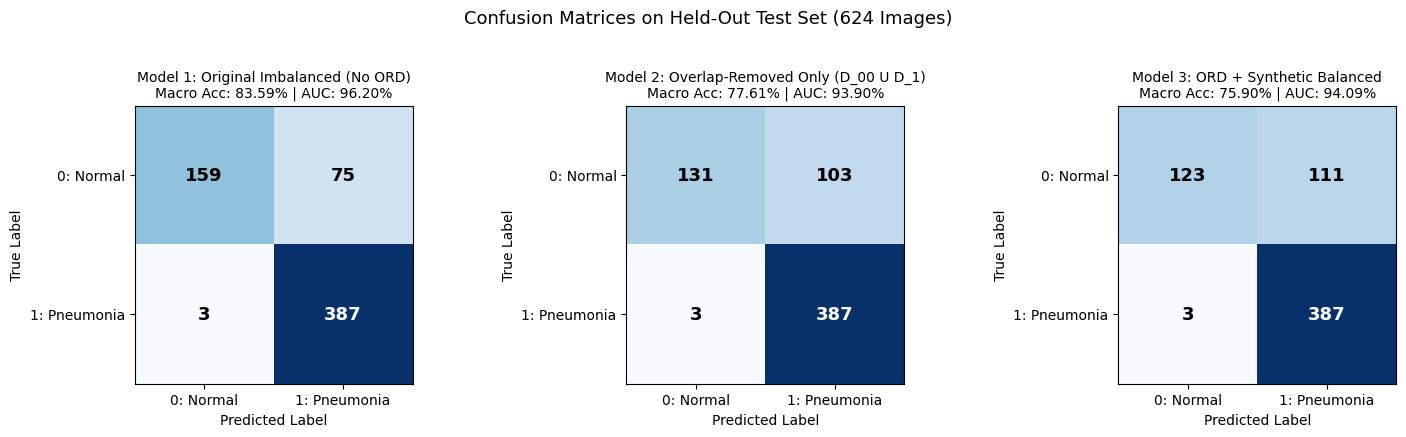

In [ ]:
all_models = [results_model_1, results_model_2, results_model_3]

print('=' * 116)
print(f"{'Model / Training Data':<42} | {'Maj:Min':>9} | {'Overall':>8} | {'Macro Acc':>9} | {'Min Acc':>8} | {'Maj Acc':>8} | {'Macro F1':>8} | {'ROC-AUC':>8}")
print('-' * 116)
for m in all_models:
    ratio_str = f"{m['n_maj']}:{m['n_min']}"
    print(f"{m['name']:<42} | {ratio_str:>9} | {m['overall_acc']:7.2f}% | {m['macro_acc']:8.2f}% | "
          f"{m['min_acc']:7.2f}% | {m['maj_acc']:7.2f}% | {m['macro_f1']:7.2f}% | {m['auc']:7.2f}%")
print('=' * 116)

# Plot Confusion Matrices Side by Side
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
class_names = ['0: Normal', '1: Pneumonia']

for ax, m in zip(axes, all_models):
    cm = m['cm']
    im = ax.imshow(cm, cmap='Blues')
    ax.set_title(f"{m['name']}\nMacro Acc: {m['macro_acc']:.2f}% | AUC: {m['auc']:.2f}%", fontsize=10)
    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(class_names)
    ax.set_yticklabels(class_names)
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')

    for i in range(2):
        for j in range(2):
            color = 'white' if cm[i, j] > cm.max() / 2 else 'black'
            ax.text(j, i, f'{cm[i, j]}', ha='center', va='center', color=color, fontsize=13, fontweight='bold')

plt.suptitle(f'Confusion Matrices on Held-Out Test Set ({len(y_test_aside)} Images)', fontsize=13, y=1.03)
plt.tight_layout()
plt.show()

## Step 6: Model 4 — Classical Augmentation Balancing (Rotation + Scaling + Gaussian Noise Instead of Synthetic Diffusion)
Instead of generating synthetic images with Conditional DDPM, we balance the overlap-removed dataset (`X_overlap_removed`) by applying **Random Rotation**, **Random Scaling**, and **Gaussian Noise** to existing images of the smaller class until **Majority Count == Minority Count**, then train ResNet-18 #4 and compare all 4 models on the exact same held-out test set.

Creating 2129 augmented Minority [Label 0] images (Rotation + Scaling + Gaussian Noise) to match 3343 Pure Majority [Label 1]...
Augmentation-balanced training counts [Normal, Pneumonia]: [3343, 3343]


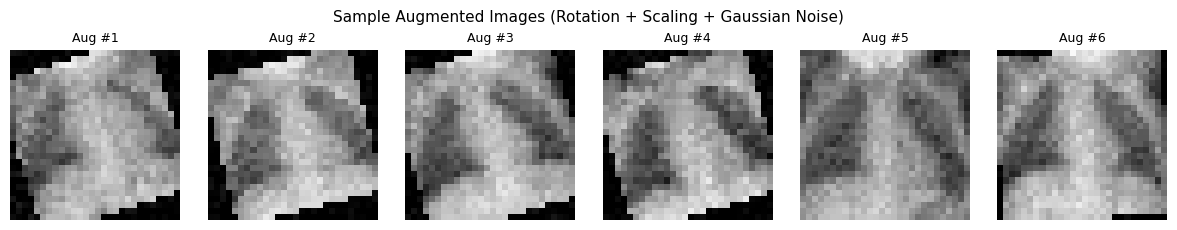

=== Model 4: ORD + Aug Balanced (Rot/Scale/Noise) ===
Training Set Size: 6686 (Maj [Label 1]: 3343, Min [Label 0]: 3343)
Overall Test Accuracy:          87.66%
Macro / Balanced Accuracy:      84.06%
Majority [1] (Pneumonia) Accuracy: 98.46%
Minority [0] (Normal) Accuracy: 69.66%
Macro F1-Score:                 85.89%
Minority [0] F1-Score:          80.89%
ROC-AUC Score:                  96.85%
Confusion Matrix (Rows=True [0:Min, 1:Maj], Cols=Predicted):
[[163  71]
 [  6 384]]

Model / Training Data                          |   Maj:Min |  Overall | Macro Acc |  Min Acc |  Maj Acc | Macro F1 |  ROC-AUC
------------------------------------------------------------------------------------------------------------------------
Model 1: Original Imbalanced (No ORD)          | 3494:1214 |   87.50% |    83.59% |   67.95% |   99.23% |   85.57% |   96.20%
Model 2: Overlap-Removed Only (D_00 U D_1)     | 3343:1214 |   83.01% |    77.61% |   55.98% |   99.23% |   79.58% |   93.90%
Model 3: ORD + Synt

In [ ]:
import torchvision.transforms.functional as TF

set_seed(42)

def augment_image_rot_scale_noise(img_tensor, max_angle=20.0, scale_range=(0.85, 1.15), noise_std=0.08):
    """Applies random rotation, random scaling, and Gaussian noise to a (1, 28, 28) tensor in [-1, 1]."""
    angle = random.uniform(-max_angle, max_angle)
    scale = random.uniform(scale_range[0], scale_range[1])
    # Apply rotation + scaling via affine transform
    aug = TF.affine(
        img_tensor,
        angle=angle,
        translate=[0, 0],
        scale=scale,
        shear=[0.0, 0.0],
        fill=-1.0
    )
    # Add Gaussian noise and clamp back to [-1, 1]
    noise = torch.randn_like(aug) * noise_std
    aug = torch.clamp(aug + noise, -1.0, 1.0)
    return aug


# Balance the overlap-removed dataset using Rotation + Scaling + Gaussian Noise
n_clear_maj = len(X_clear_maj)
n_real_min  = len(X_min)
diff_count  = abs(n_clear_maj - n_real_min)

if n_clear_maj >= n_real_min:
    source_pool = X_min
    aug_label = 0  # Minority [Label 0]
    print(f'Creating {diff_count} augmented Minority [Label 0] images (Rotation + Scaling + Gaussian Noise) to match {n_clear_maj} Pure Majority [Label 1]...')
else:
    source_pool = X_clear_maj
    aug_label = 1  # Pure Majority [Label 1]
    print(f'Creating {diff_count} augmented Pure Majority [Label 1] images (Rotation + Scaling + Gaussian Noise) to match {n_real_min} Minority [Label 0]...')

aug_images = []
for _ in range(diff_count):
    idx = random.randint(0, len(source_pool) - 1)
    aug_img = augment_image_rot_scale_noise(source_pool[idx])
    aug_images.append(aug_img)

X_aug_extra = torch.stack(aug_images, dim=0) if aug_images else X_overlap_removed[:0].clone()
y_aug_extra = torch.full((diff_count,), aug_label, dtype=torch.long)

X_balanced_aug = torch.cat([X_overlap_removed, X_aug_extra], dim=0)
y_balanced_aug = torch.cat([y_overlap_removed, y_aug_extra], dim=0)
counts = torch.bincount(y_balanced_aug, minlength=2)
assert counts[0] == counts[1]
print(f'Augmentation-balanced training counts [Normal, Pneumonia]: {counts.tolist()}')

# Visualize sample augmented images
n_show = min(6, len(X_aug_extra))
if n_show > 0:
    fig, axes = plt.subplots(1, n_show, figsize=(2 * n_show, 2.3))
    if n_show == 1:
        axes = [axes]
    for i in range(n_show):
        axes[i].imshow(X_aug_extra[i, 0].numpy(), cmap='gray', vmin=-1, vmax=1)
        axes[i].set_title(f'Aug #{i+1}', fontsize=9)
        axes[i].axis('off')
    plt.suptitle('Sample Augmented Images (Rotation + Scaling + Gaussian Noise)', fontsize=11)
    plt.tight_layout()
    plt.show()

# Train Model 4 on the Augmentation-Balanced Dataset and evaluate on the held-out testing data
results_model_4 = train_and_evaluate_resnet18(
    X_balanced_aug,
    y_balanced_aug,
    X_test_aside,
    y_test_aside,
    model_name='Model 4: ORD + Aug Balanced (Rot/Scale/Noise)'
)

# Updated Side-by-Side Comparison of All 4 Models
all_4_models = [results_model_1, results_model_2, results_model_3, results_model_4]

print('\n' + '=' * 120)
print(f"{'Model / Training Data':<46} | {'Maj:Min':>9} | {'Overall':>8} | {'Macro Acc':>9} | {'Min Acc':>8} | {'Maj Acc':>8} | {'Macro F1':>8} | {'ROC-AUC':>8}")
print('-' * 120)
for m in all_4_models:
    ratio_str = f"{m['n_maj']}:{m['n_min']}"
    print(f"{m['name']:<46} | {ratio_str:>9} | {m['overall_acc']:7.2f}% | {m['macro_acc']:8.2f}% | "
          f"{m['min_acc']:7.2f}% | {m['maj_acc']:7.2f}% | {m['macro_f1']:7.2f}% | {m['auc']:7.2f}%")
print('=' * 120)

## Step 7: Final Four-Model Comparison and Per-Class Improvements
Class accuracy is recall (correctly classified images divided by the number of true images of that class). Improvements are percentage-point changes relative to the original imbalanced baseline. All metrics use the identical official test split.

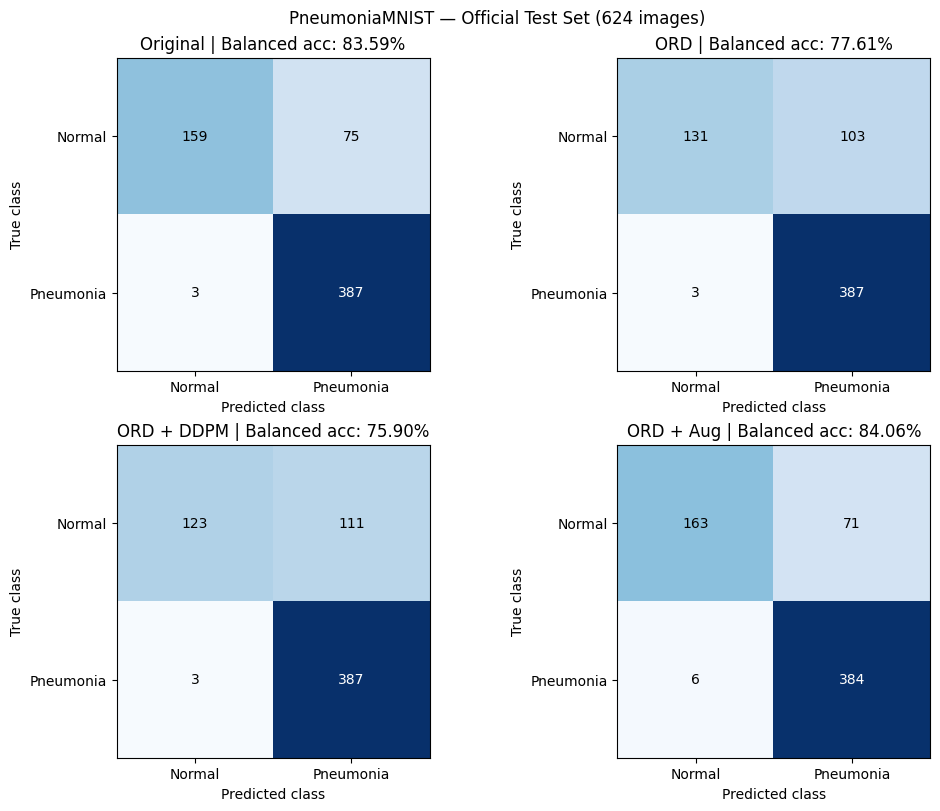

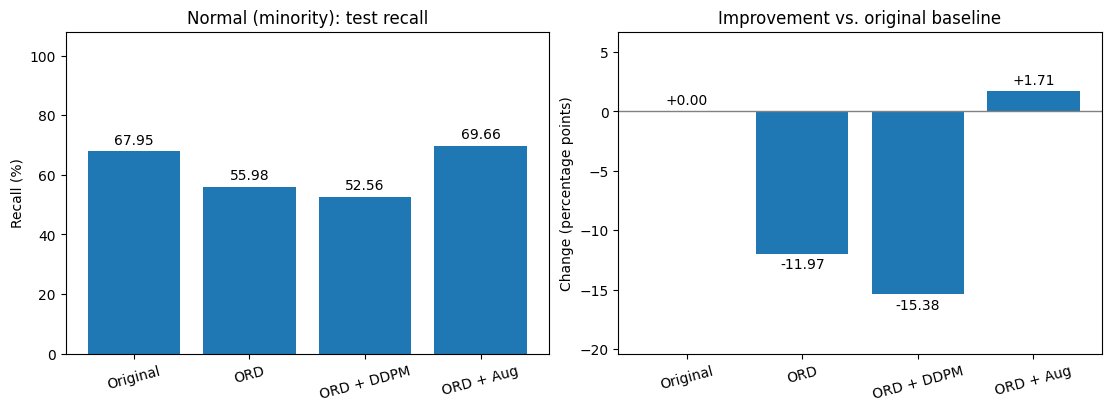

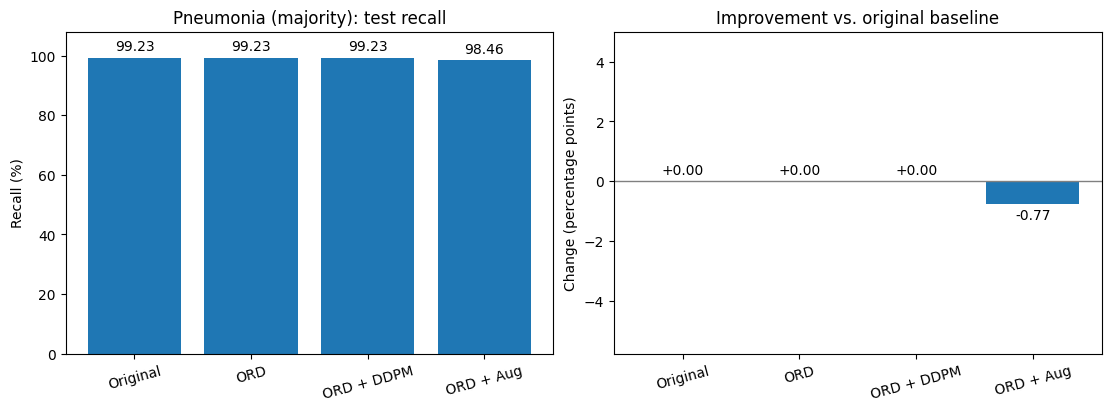

In [ ]:
model_labels = ['Original', 'ORD', 'ORD + DDPM', 'ORD + Aug']
assert all(np.array_equal(m['y_true'], y_test_aside.numpy()) for m in all_4_models)

fig, axes = plt.subplots(2, 2, figsize=(10, 8), constrained_layout=True)
max_count = max(m['cm'].max() for m in all_4_models)
for ax, m, name in zip(axes.flat, all_4_models, model_labels):
    cm = m['cm']
    ax.imshow(cm, cmap='Blues', vmin=0, vmax=max_count)
    ax.set_title(f'{name} | Balanced acc: {m["macro_acc"]:.2f}%')
    ax.set_xticks([0, 1], ['Normal', 'Pneumonia'])
    ax.set_yticks([0, 1], ['Normal', 'Pneumonia'])
    ax.set_xlabel('Predicted class')
    ax.set_ylabel('True class')
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]), ha='center', va='center',
                    color='white' if cm[i, j] > max_count / 2 else 'black')
fig.suptitle(f'PneumoniaMNIST — Official Test Set ({len(y_test_aside)} images)')
plt.show()

for key, class_name in [('min_acc', 'Normal (minority)'), ('maj_acc', 'Pneumonia (majority)')]:
    values = np.array([m[key] for m in all_4_models])
    deltas = values - values[0]
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
    bars = axes[0].bar(model_labels, values)
    axes[0].bar_label(bars, fmt='%.2f', padding=3)
    axes[0].set_ylim(0, 108)
    axes[0].set_ylabel('Recall (%)')
    axes[0].set_title(f'{class_name}: test recall')
    bars = axes[1].bar(model_labels, deltas)
    axes[1].bar_label(bars, fmt='%+.2f', padding=3)
    axes[1].axhline(0, color='gray', linewidth=1)
    axes[1].set_ylim(min(-5, deltas.min()-5), max(5, deltas.max()+5))
    axes[1].set_ylabel('Change (percentage points)')
    axes[1].set_title('Improvement vs. original baseline')
    for ax in axes:
        ax.tick_params(axis='x', labelrotation=15)
    plt.show()